# EDA mùa vụ – M5 CA_1 × FOODS_3
Chỉ dùng split **train** (không nhìn val/test); các thống kê mùa vụ tính từ ngày bán đầu tiên của từng chuỗi.

In [1]:
import sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd
from src import eda
data = pd.read_parquet(ROOT / 'data/processed/ca1_foods3.parquet')
train = eda.load_train(data)
act = eda.active_rows(train)
print('train rows:', len(train), '| sau ngày ra mắt:', len(act), '| số chuỗi:', train['id'].nunique())

train rows: 1551355 | sau ngày ra mắt: 1232461 | số chuỗi: 823


In [2]:
tables = eda.seasonality_tables(act)
(ROOT / 'results/tables').mkdir(parents=True, exist_ok=True)
for k, t in tables.items():
    t.to_csv(ROOT / f'results/tables/eda_{k}.csv', index=False)
    print('==', k); print(t.round(4).to_string(index=False))

== weekday
  weekday  mean_y  index_vs_mean
   Monday  2.9874         0.9523
  Tuesday  2.6134         0.8331
Wednesday  2.5597         0.8160
 Thursday  2.5949         0.8272
   Friday  3.1364         0.9998
 Saturday  3.9512         1.2596
   Sunday  4.1099         1.3102
== month
 month  mean_y  index_vs_mean
     1  2.8860         0.9200
     2  3.0253         0.9644
     3  3.0812         0.9822
     4  3.2703         1.0425
     5  3.2136         1.0244
     6  3.3290         1.0612
     7  3.3105         1.0553
     8  3.4019         1.0845
     9  3.2555         1.0378
    10  3.1163         0.9934
    11  2.9713         0.9472
    12  2.8454         0.9071
== snap
 snap_CA  mean_y
       0  3.0195
       1  3.3778
== event_flag
 has_event  mean_y
     False  3.1480
      True  3.0128
== event_type
event_type_1  mean_y  n_rows  index_vs_mean
    Cultural  3.1281   22810         0.9972
    National  2.7672   33788         0.8821
   Religious  3.0750   33836         0.9803
    Sp

results/figures/eda_trend_total.png


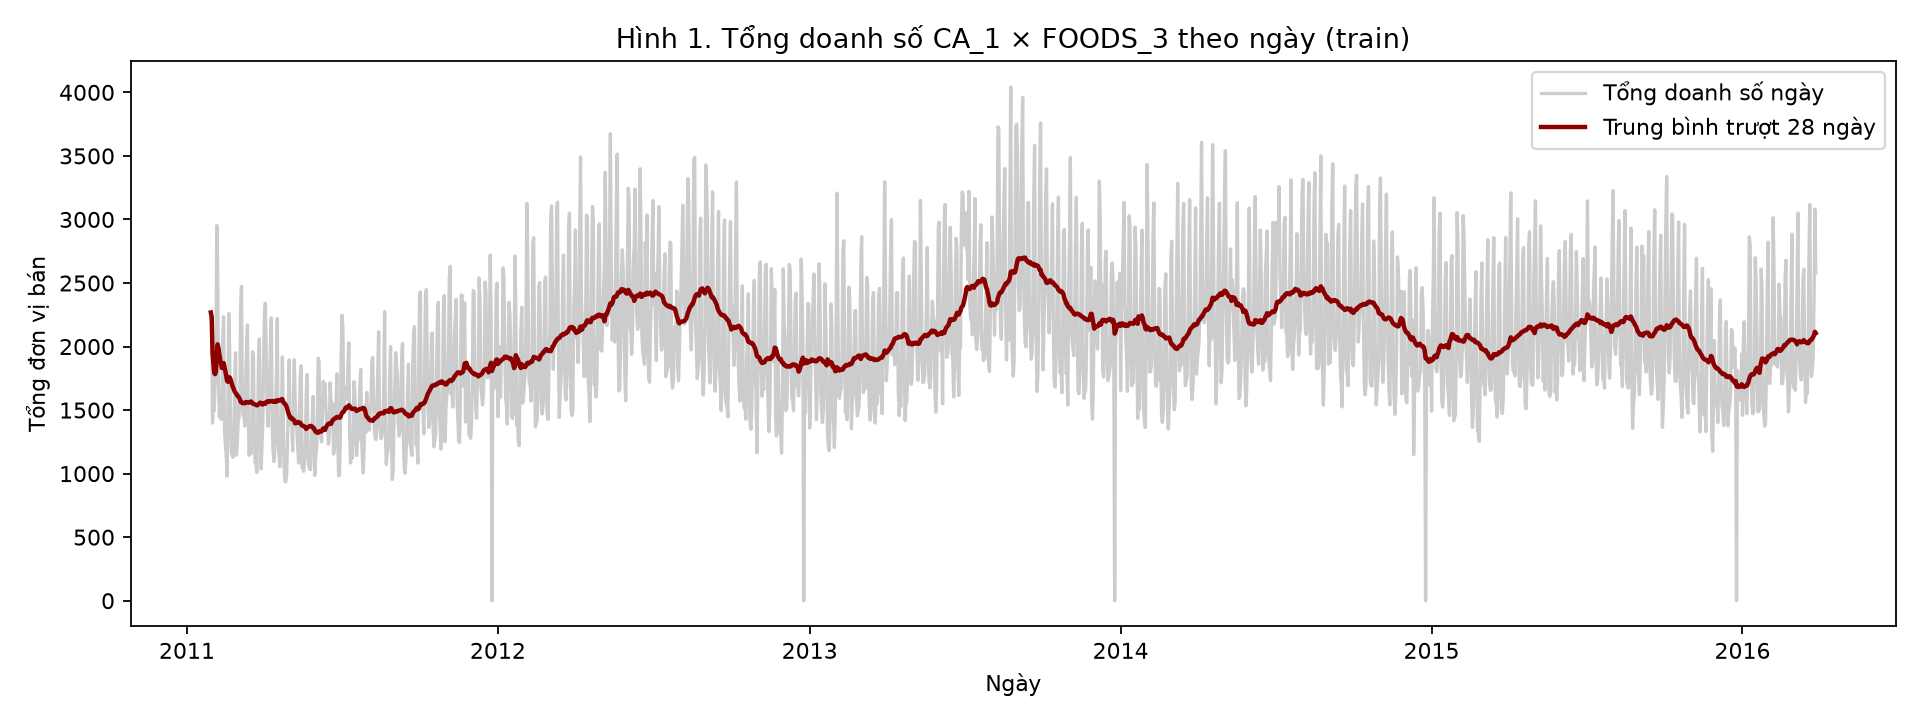

results/figures/eda_weekday.png


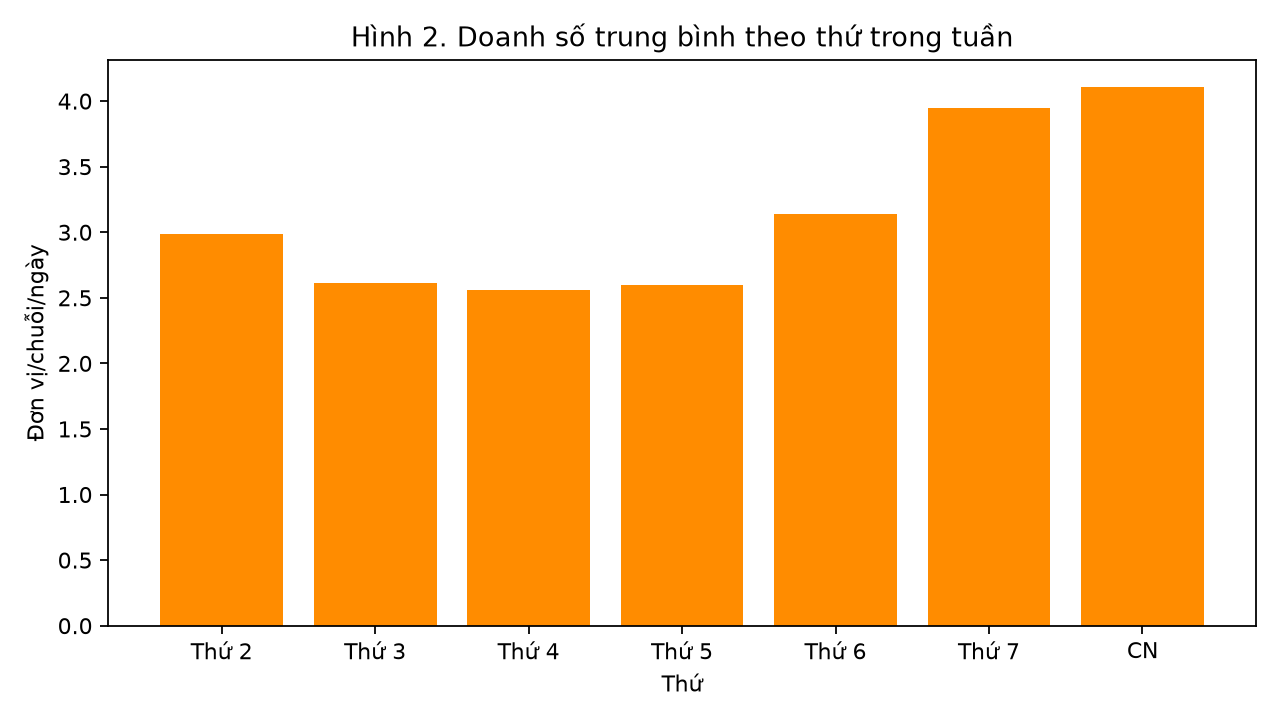

results/figures/eda_month.png


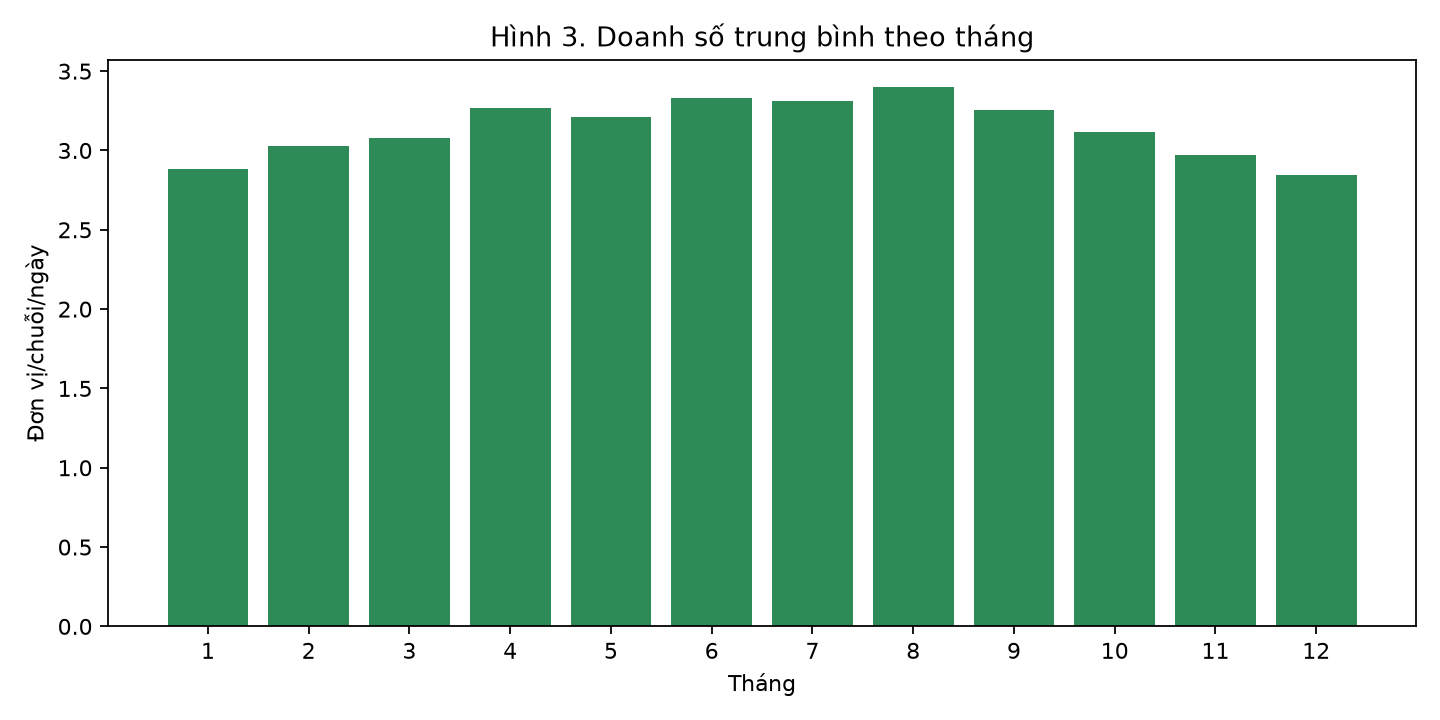

results/figures/eda_snap_event.png


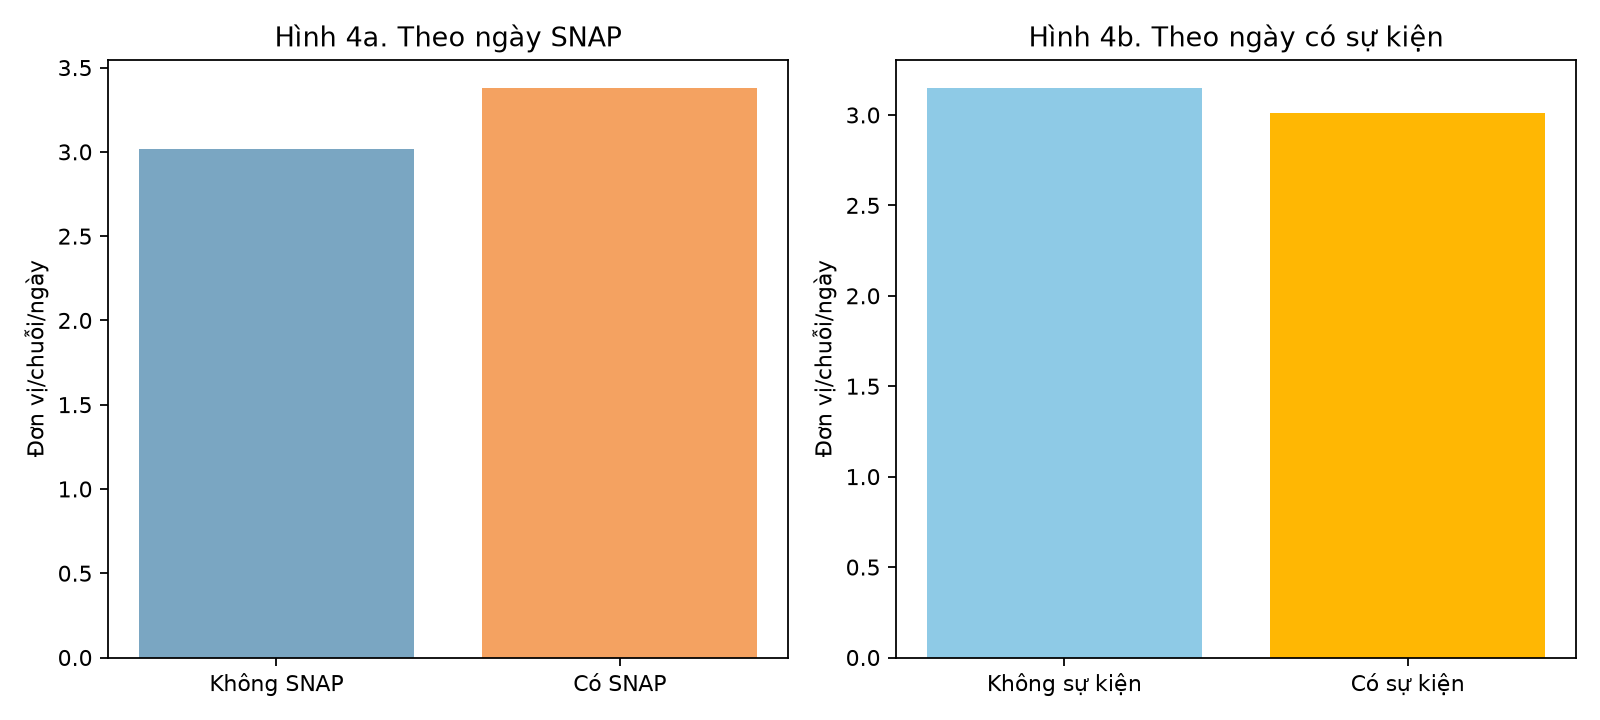

results/figures/eda_event_names.png


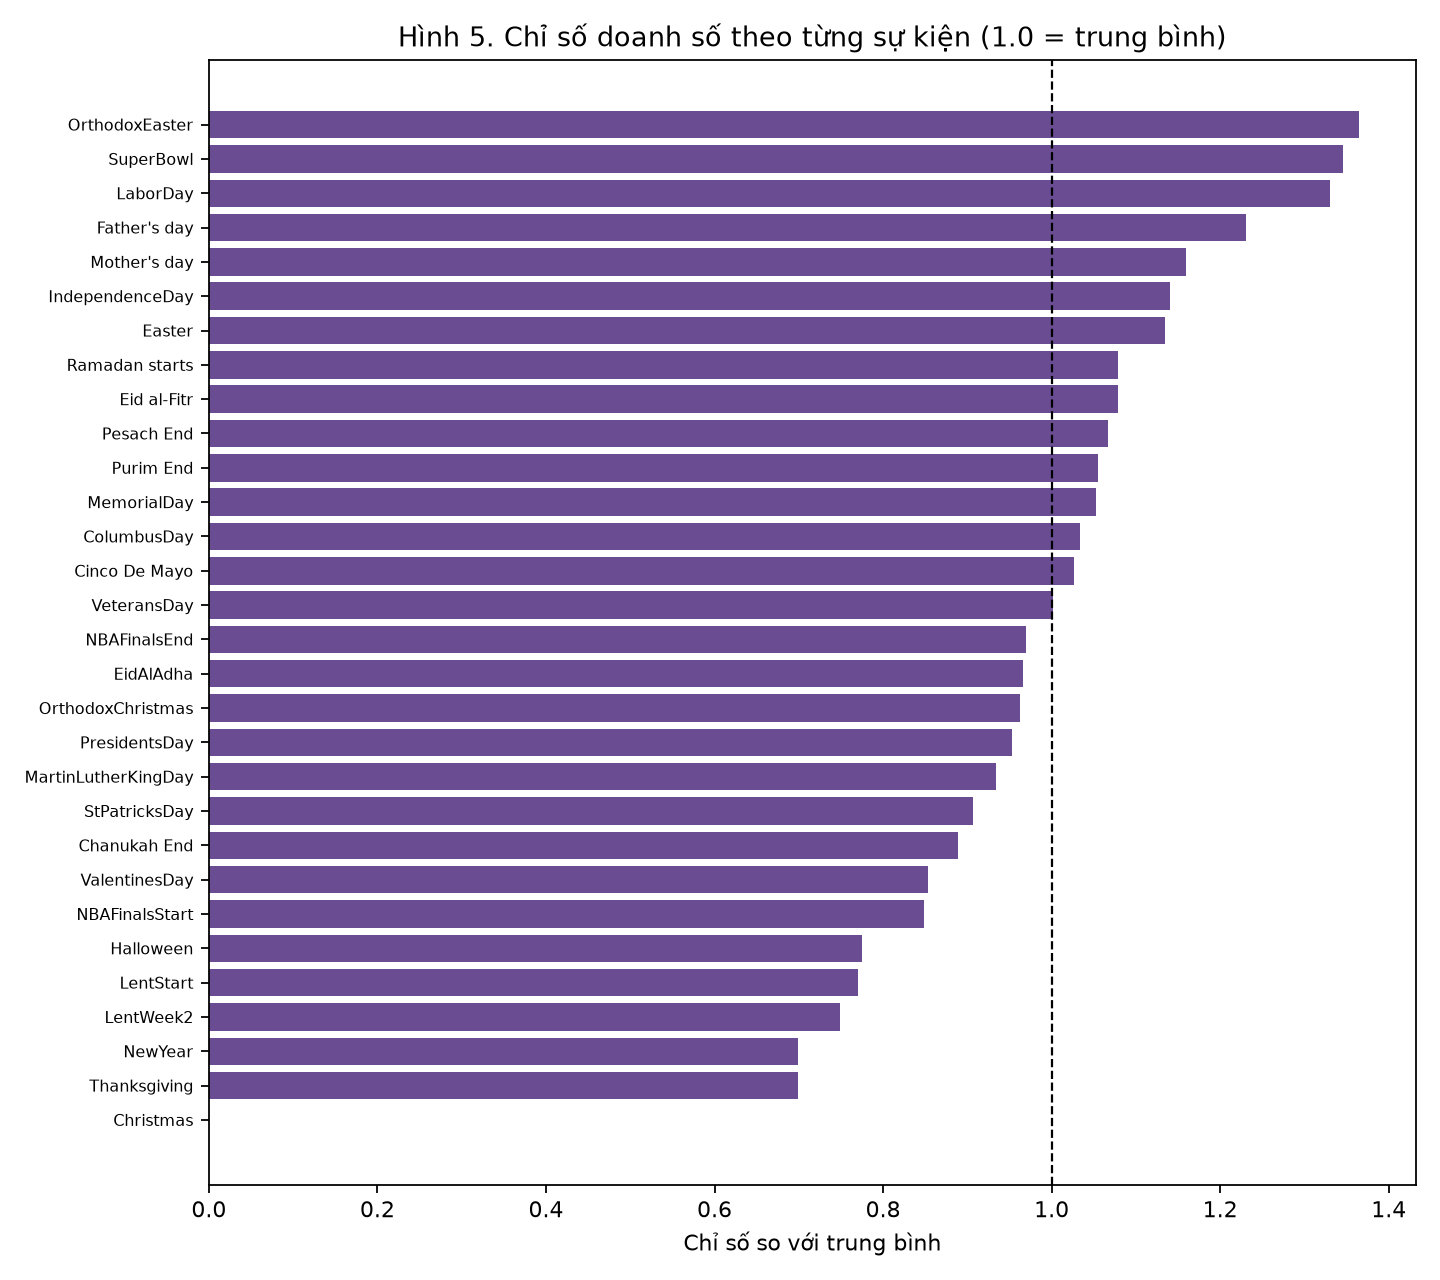

results/figures/eda_zero_rate.png


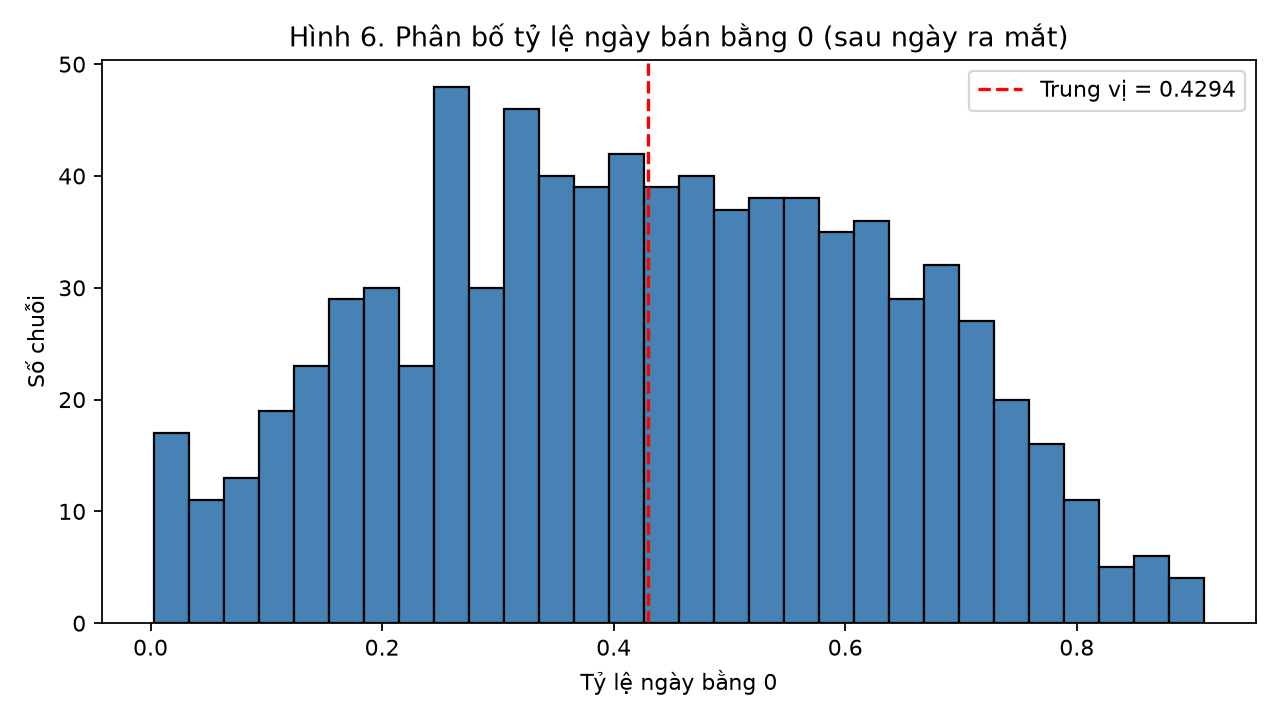

In [3]:
paths = eda.plot_all(train, act, tables)
from IPython.display import Image, display
for p in paths:
    print(p); display(Image(str(ROOT / p), width=700))

Nhận xét: xem `results/reports/01_eda.md` (số liệu lấy từ các bảng ở trên).